In [2]:
import gymnasium as gym

from stable_baselines3.common.monitor import Monitor
from stable_baselines3 import DQN, PPO
from stable_baselines3.common.evaluation import evaluate_policy

---
### Etape 1 Exploration de lunar landing

#### Exploration de l'environnement

In [ ]:
env = gym.make("LunarLander-v3")

print("env.observation_space : ")
print(env.observation_space)
print("--------------------------")
print("env.action_space :")
print(env.action_space)

env.observation_space : 
Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
--------------------------
env.action_space :
Discrete(4)


Donc :
- 8 variables
- 4 actions

#### Entraînement d'un premier agent

In [5]:
model = DQN(
    "MlpPolicy",
    env,
    verbose=1
)
model.learn(total_timesteps=100000)

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 74.8     |
|    ep_rew_mean      | -96.1    |
|    exploration_rate | 0.972    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 1838     |
|    time_elapsed     | 0        |
|    total_timesteps  | 299      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 4.03     |
|    n_updates        | 49       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 79.6     |
|    ep_rew_mean      | -144     |
|    exploration_rate | 0.939    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 1486     |
|    time_elapsed     | 0        |
|    total_timesteps  | 637      |
| train/              |        

#### Évaluation

In [6]:
mean_reward, std_reward = evaluate_policy(
    model,
    env,
    n_eval_episodes=50,
    deterministic=True
)

h:\python_project\projet11\.venv\Lib\site-packages\stable_baselines3\common\evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


In [7]:
print(f"Récompense moyenne : {mean_reward:.2f}")
print(f"Ecart-type : {std_reward:.2f}")

Récompense moyenne : -96.70
Ecart-type : 87.70


#### Visuel

In [8]:
env = gym.make("LunarLander-v3", render_mode="human")

obs, info = env.reset()

done = False

while not done:
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated

env.close()

---
### Etape 2 Optimisation

In [2]:
env = gym.make("LunarLander-v3", render_mode="rgb_array")

#### Baseline

In [39]:
train_env = Monitor(gym.make("LunarLander-v3"))
eval_env = Monitor(gym.make("LunarLander-v3"))


model = DQN(
    "MlpPolicy",
    train_env,
    verbose=1,
    tensorboard_log="./tensorboard_logs/",
    seed=42
)


model.learn(
    total_timesteps=500000,
    tb_log_name="baseline_500k"
)


mean_reward, std_reward = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=100,
    deterministic=True
)


print(f"Baseline : {mean_reward:.2f} ± {std_reward:.2f}")

Using cpu device
Wrapping the env in a DummyVecEnv.
Logging to ./tensorboard_logs/baseline_500k_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 94.5     |
|    ep_rew_mean      | -208     |
|    exploration_rate | 0.993    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 989      |
|    time_elapsed     | 0        |
|    total_timesteps  | 378      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 5.01     |
|    n_updates        | 69       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 88.2     |
|    ep_rew_mean      | -159     |
|    exploration_rate | 0.987    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 1061     |
|    time_elapsed     | 0        |
|    total_timesteps  | 706      |
| train/              |    

#### Learning Rate

In [18]:
model = DQN(
    "MlpPolicy",
    env,
    learning_rate=5e-4,
    verbose=1,
    tensorboard_log="./tensorboard_logs/"
)

model.learn(
    total_timesteps=100000,
    tb_log_name="learning_rate"
)

mean_reward, std_reward = evaluate_policy(
    model,
    env,
    n_eval_episodes=100,
    deterministic=True
)

print(f"Learning Rate : {mean_reward:.2f} ± {std_reward:.2f}")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./tensorboard_logs/learning_rate_1


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 90.2     |
|    ep_rew_mean      | -252     |
|    exploration_rate | 0.966    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 1352     |
|    time_elapsed     | 0        |
|    total_timesteps  | 361      |
| train/              |          |
|    learning_rate    | 0.0005   |
|    loss             | 1.19     |
|    n_updates        | 65       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 88.2     |
|    ep_rew_mean      | -171     |
|    exploration_rate | 0.933    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 1251     |
|    time_elapsed     | 0        |
|    total_timesteps  | 706      |
| train/              |          |
|    learning_rate    | 0.0005   |
|    loss             | 0.414    |
|    n_updates      

#### Gamma

In [19]:
model = DQN(
    "MlpPolicy",
    env,
    gamma=0.995,
    verbose=1,
    tensorboard_log="./tensorboard_logs/"
)

model.learn(
    total_timesteps=100000,
    tb_log_name="gamma"
)

mean_reward, std_reward = evaluate_policy(
    model,
    env,
    n_eval_episodes=100,
    deterministic=True
)

print(f"Gamma : {mean_reward:.2f} ± {std_reward:.2f}")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./tensorboard_logs/gamma_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 104      |
|    ep_rew_mean      | -126     |
|    exploration_rate | 0.96     |
| time/               |          |
|    episodes         | 4        |
|    fps              | 1370     |
|    time_elapsed     | 0        |
|    total_timesteps  | 418      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.985    |
|    n_updates        | 79       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 101      |
|    ep_rew_mean      | -170     |
|    exploration_rate | 0.923    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 1256     |
|    time_elapsed     | 0        |
|    total_timesteps  | 808 

#### Buffer Size

In [20]:
model = DQN(
    "MlpPolicy",
    env,
    buffer_size=200000,
    verbose=1,
    tensorboard_log="./tensorboard_logs/"
)

model.learn(
    total_timesteps=100000,
    tb_log_name="buffer_size"
)

mean_reward, std_reward = evaluate_policy(
    model,
    env,
    n_eval_episodes=100,
    deterministic=True
)

print(f"Buffer Size : {mean_reward:.2f} ± {std_reward:.2f}")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./tensorboard_logs/buffer_size_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 98.5     |
|    ep_rew_mean      | -271     |
|    exploration_rate | 0.963    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 1433     |
|    time_elapsed     | 0        |
|    total_timesteps  | 394      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 1.2      |
|    n_updates        | 73       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 101      |
|    ep_rew_mean      | -270     |
|    exploration_rate | 0.923    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 1258     |
|    time_elapsed     | 0        |
|    total_timesteps  

#### Batch Size

In [21]:
model = DQN(
    "MlpPolicy",
    env,
    batch_size=128,
    verbose=1,
    tensorboard_log="./tensorboard_logs/"
)

model.learn(
    total_timesteps=100000,
    tb_log_name="batch_size"
)

mean_reward, std_reward = evaluate_policy(
    model,
    env,
    n_eval_episodes=100,
    deterministic=True
)

print(f"Batch Size : {mean_reward:.2f} ± {std_reward:.2f}")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./tensorboard_logs/batch_size_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 78.2     |
|    ep_rew_mean      | -121     |
|    exploration_rate | 0.97     |
| time/               |          |
|    episodes         | 4        |
|    fps              | 1431     |
|    time_elapsed     | 0        |
|    total_timesteps  | 313      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 1.76     |
|    n_updates        | 53       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 191      |
|    ep_rew_mean      | -99.9    |
|    exploration_rate | 0.855    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 683      |
|    time_elapsed     | 2        |
|    total_timesteps  |

#### Exploration

In [22]:
model = DQN(
    "MlpPolicy",
    env,
    exploration_fraction=0.2,
    exploration_final_eps=0.02,
    verbose=1,
    tensorboard_log="./tensorboard_logs/"
)

model.learn(
    total_timesteps=100000,
    tb_log_name="exploration"
)

mean_reward, std_reward = evaluate_policy(
    model,
    env,
    n_eval_episodes=100,
    deterministic=True
)

print(f"Exploration : {mean_reward:.2f} ± {std_reward:.2f}")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./tensorboard_logs/exploration_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 82.8     |
|    ep_rew_mean      | -116     |
|    exploration_rate | 0.984    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 1308     |
|    time_elapsed     | 0        |
|    total_timesteps  | 331      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 1.01     |
|    n_updates        | 57       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 93.2     |
|    ep_rew_mean      | -157     |
|    exploration_rate | 0.963    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 1271     |
|    time_elapsed     | 0        |
|    total_timesteps  

### Résultats Pas à Pas

| Expérience    | Récompense moyenne | Écart-type | Interprétation                                                                              |
| ------------- | -----------------: | ---------: | ------------------------------------------------------------------------------------------- |
| Baseline      |           **8.88** |     181.53 | L'agent apprend peu, comportement très variable.                                            |
| Learning Rate |        **-126.45** |      23.95 | Cette valeur de `learning_rate` dégrade les performances.                                   |
| Gamma         |           **8.51** |     153.92 | Peu de différence par rapport à la baseline.                                                |
| Buffer Size   |        **-102.00** |      42.81 | Pas d'amélioration.                                                                         |
| Batch Size    |        **-103.20** |      97.23 | Pas d'amélioration.                                                                         |
| Exploration   |          **53.26** |     145.75 | C'est le meilleur résultat obtenu jusqu'à présent, mais il reste loin de l'objectif de 200. |


#### TensorBoard

In [55]:
%load_ext tensorboard
%tensorboard --logdir ./tensorboard_logs/


The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 5080), started 0:00:21 ago. (Use '!kill 5080' to kill it.)

---
#### Test meilleurs hyperparamètres

In [ ]:
train_env = Monitor(gym.make("LunarLander-v3"))
eval_env = Monitor(gym.make("LunarLander-v3"))


model = DQN(
    "MlpPolicy",
    train_env,
    verbose=1,
    tensorboard_log="./tensorboard_logs/",
    seed=42
)


model.learn(
    total_timesteps=500000,
    tb_log_name="baseline_500k"
)


mean_reward, std_reward = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=100,
    deterministic=True
)


print(f"Baseline : {mean_reward:.2f} ± {std_reward:.2f}")

Using cpu device
Wrapping the env in a DummyVecEnv.
Logging to ./tensorboard_logs/baseline_500k_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 94.5     |
|    ep_rew_mean      | -208     |
|    exploration_rate | 0.993    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 989      |
|    time_elapsed     | 0        |
|    total_timesteps  | 378      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 5.01     |
|    n_updates        | 69       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 88.2     |
|    ep_rew_mean      | -159     |
|    exploration_rate | 0.987    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 1061     |
|    time_elapsed     | 0        |
|    total_timesteps  | 706      |
| train/              |    

#### Baseline Test

In [23]:
model = DQN(
    "MlpPolicy",
    env,
    exploration_fraction=0.2,
    exploration_final_eps=0.02,
    verbose=1,
    tensorboard_log="./tensorboard_logs/"
)

model.learn(
    total_timesteps=500000,
    tb_log_name="final_model"
)

mean_reward, std_reward = evaluate_policy(
    model,
    env,
    n_eval_episodes=100,
    deterministic=True
)

print(f"Final : {mean_reward:.2f} ± {std_reward:.2f}")

model.save("best_model")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./tensorboard_logs/final_model_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 93.5     |
|    ep_rew_mean      | -313     |
|    exploration_rate | 0.996    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 1189     |
|    time_elapsed     | 0        |
|    total_timesteps  | 374      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 3.54     |
|    n_updates        | 68       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 85.5     |
|    ep_rew_mean      | -231     |
|    exploration_rate | 0.993    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 1158     |
|    time_elapsed     | 0        |
|    total_timesteps  

In [24]:
model = DQN(
    "MlpPolicy",
    env,
    learning_rate=5e-5,
    gamma=0.995,
    buffer_size=500000,
    batch_size=64,
    exploration_fraction=0.2,
    exploration_final_eps=0.02,
    target_update_interval=5000,
    verbose=1,
    tensorboard_log="./tensorboard_logs/",
    seed=42
)

model.learn(
    total_timesteps=1000000,
    tb_log_name="optimized_final"
)


Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./tensorboard_logs/optimized_final_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 95.5     |
|    ep_rew_mean      | -180     |
|    exploration_rate | 0.998    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 1225     |
|    time_elapsed     | 0        |
|    total_timesteps  | 382      |
| train/              |          |
|    learning_rate    | 5e-05    |
|    loss             | 2.1      |
|    n_updates        | 70       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 93.2     |
|    ep_rew_mean      | -209     |
|    exploration_rate | 0.996    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 1216     |
|    time_elapsed     | 0        |
|    total_timeste

In [25]:
mean_reward, std_reward = evaluate_policy(
    model,
    env,
    n_eval_episodes=100,
    deterministic=True
)

print(f"Final : {mean_reward:.2f} ± {std_reward:.2f}")

model.save("best_model")

Final : -28.49 ± 82.67


#### Optimisation automatisée Optuna

In [36]:
import gymnasium as gym
import optuna

from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.evaluation import evaluate_policy

# -------------------------
# Environnements
# -------------------------

train_env = Monitor(gym.make("LunarLander-v3"))
eval_env = Monitor(gym.make("LunarLander-v3"))

train_env.reset(seed=42)
eval_env.reset(seed=42)

# -------------------------
# Fonction objectif Optuna
# -------------------------

def objective(trial):

    learning_rate = trial.suggest_float(
        "learning_rate",
        1e-5,
        1e-3,
        log=True
    )

    gamma = trial.suggest_categorical(
        "gamma",
        [0.95, 0.98, 0.99, 0.995, 0.999]
    )

    batch_size = trial.suggest_categorical(
        "batch_size",
        [32, 64, 128, 256]
    )

    exploration_fraction = trial.suggest_float(
        "exploration_fraction",
        0.05,
        0.5
    )

    exploration_final_eps = trial.suggest_categorical(
        "exploration_final_eps",
        [0.01, 0.02, 0.05, 0.1]
    )

    train_freq = trial.suggest_categorical(
        "train_freq",
        [1, 4, 8]
    )

    gradient_steps = trial.suggest_categorical(
        "gradient_steps",
        [1, 2, 4, 8]
    )

    model = DQN(
        "MlpPolicy",
        train_env,
        learning_rate=learning_rate,
        gamma=gamma,
        batch_size=batch_size,
        exploration_fraction=exploration_fraction,
        exploration_final_eps=exploration_final_eps,
        train_freq=train_freq,
        gradient_steps=gradient_steps,
        verbose=0,
        seed=42
    )

    model.learn(
        total_timesteps=100000
    )

    mean_reward, _ = evaluate_policy(
        model,
        eval_env,
        n_eval_episodes=20,
        deterministic=True
    )

    return mean_reward


# -------------------------
# Recherche Optuna
# -------------------------

study = optuna.create_study(direction="maximize")

study.optimize(
    objective,
    n_trials=20
)

print("Meilleurs paramètres :")
print(study.best_params)

print("Meilleure récompense :")
print(study.best_value)

[I 2026-07-14 17:36:35,668] A new study created in memory with name: no-name-b20a9e03-e6ca-4a3f-8b6e-0b13b1b672b2
[I 2026-07-14 17:39:40,457] Trial 0 finished with value: -106.93328689999998 and parameters: {'learning_rate': 0.0002566830211635328, 'gamma': 0.98, 'batch_size': 64, 'exploration_fraction': 0.45901199279751775, 'exploration_final_eps': 0.1, 'train_freq': 4, 'gradient_steps': 2}. Best is trial 0 with value: -106.93328689999998.
[I 2026-07-14 18:23:13,953] Trial 1 finished with value: -141.2619905 and parameters: {'learning_rate': 2.703688582166612e-05, 'gamma': 0.95, 'batch_size': 256, 'exploration_fraction': 0.4586621777387647, 'exploration_final_eps': 0.02, 'train_freq': 1, 'gradient_steps': 8}. Best is trial 0 with value: -106.93328689999998.
[I 2026-07-14 18:26:45,542] Trial 2 finished with value: -119.47263294999998 and parameters: {'learning_rate': 0.00013565049472814868, 'gamma': 0.98, 'batch_size': 32, 'exploration_fraction': 0.2449127881158838, 'exploration_final_e

Meilleurs paramètres :
{'learning_rate': 1.361543960445859e-05, 'gamma': 0.999, 'batch_size': 256, 'exploration_fraction': 0.14735178496837267, 'exploration_final_eps': 0.01, 'train_freq': 8, 'gradient_steps': 4}
Meilleure récompense :
98.86582734999999


In [ ]:
best_params = study.best_params

model = DQN(
    "MlpPolicy",
    train_env,
    **best_params,
    verbose=1,
    tensorboard_log="./tensorboard_logs/",
    seed=42
)

model.learn(
    total_timesteps=1000000,
    tb_log_name="optuna_best"
)

mean_reward, std_reward = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=100,
    deterministic=True
)

print(f"Score final : {mean_reward:.2f} ± {std_reward:.2f}")

model.save("best_model_optuna")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./tensorboard_logs/optuna_best_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 86       |
|    ep_rew_mean      | -160     |
|    exploration_rate | 0.997    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 1203     |
|    time_elapsed     | 0        |
|    total_timesteps  | 344      |
| train/              |          |
|    learning_rate    | 4.01e-05 |
|    loss             | 1.84     |
|    n_updates        | 60       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 87.8     |
|    ep_rew_mean      | -192     |
|    exploration_rate | 0.994    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 1208     |
|    time_elapsed     | 0        |
|    total_timesteps  

In [42]:
import gymnasium as gym

from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.evaluation import evaluate_policy


# Environnements séparés
train_env = Monitor(gym.make("LunarLander-v3"))
eval_env = Monitor(gym.make("LunarLander-v3"))


# Modèle DQN
model = DQN(
    "MlpPolicy",
    train_env,
    learning_rate=5e-5,
    buffer_size=1000000,
    learning_starts=50000,
    batch_size=64,
    gamma=0.99,
    train_freq=4,
    gradient_steps=1,
    target_update_interval=10000,
    exploration_fraction=0.1,
    exploration_final_eps=0.05,
    verbose=1,
    tensorboard_log="./tensorboard_logs/"
)


# Entraînement
model.learn(
    total_timesteps=1000000,
    tb_log_name="dqn_lunarlander_test"
)


# Évaluation sur 100 épisodes
mean_reward, std_reward = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=100,
    deterministic=True
)


print(f"Score final : {mean_reward:.2f} ± {std_reward:.2f}")


# Sauvegarde
model.save("dqn_lunarlander_test")


# Fermeture propre
train_env.close()
eval_env.close()

Using cpu device
Wrapping the env in a DummyVecEnv.
Logging to ./tensorboard_logs/dqn_lunarlander_test_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 85.5     |
|    ep_rew_mean      | -128     |
|    exploration_rate | 0.997    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 5205     |
|    time_elapsed     | 0        |
|    total_timesteps  | 342      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 89.5     |
|    ep_rew_mean      | -134     |
|    exploration_rate | 0.993    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 5283     |
|    time_elapsed     | 0        |
|    total_timesteps  | 716      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 89.1     |
|    ep_rew_mean    

In [48]:
from stable_baselines3 import DQN

train_env = Monitor(gym.make("LunarLander-v3"))
eval_env = Monitor(gym.make("LunarLander-v3"))

train_env.reset(seed=42)
eval_env.reset(seed=42)

model = DQN(
    "MlpPolicy",
    train_env,
    learning_rate=1e-4,
    buffer_size=500000,
    learning_starts=10000,
    batch_size=64,
    gamma=0.99,
    train_freq=4,
    gradient_steps=1,
    target_update_interval=10000,
    exploration_fraction=0.1,
    exploration_final_eps=0.05,
    verbose=1,
    tensorboard_log="./tensorboard_logs/"
)

model.learn(
    total_timesteps=2000000,
    tb_log_name="dqn_test_2M"
)

Using cpu device
Wrapping the env in a DummyVecEnv.
Logging to ./tensorboard_logs/dqn_test_2M_2
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 90       |
|    ep_rew_mean      | -135     |
|    exploration_rate | 0.998    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 6403     |
|    time_elapsed     | 0        |
|    total_timesteps  | 360      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 92.6     |
|    ep_rew_mean      | -149     |
|    exploration_rate | 0.996    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 6789     |
|    time_elapsed     | 0        |
|    total_timesteps  | 741      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 92.5     |
|    ep_rew_mean      | -188 

In [50]:
# Évaluation sur 100 épisodes
mean_reward, std_reward = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=100,
    deterministic=True
)
print(f"Score final : {mean_reward:.2f} ± {std_reward:.2f}")

Score final : 184.69 ± 97.13


In [53]:
model.learn(
    total_timesteps=3000000,
    tb_log_name="dqn_test_3M"
)

# Évaluation sur 100 épisodes
mean_reward, std_reward = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=100,
    deterministic=True
)
print(f"Score final : {mean_reward:.2f} ± {std_reward:.2f}")

Logging to ./tensorboard_logs/dqn_test_3M_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 106      |
|    ep_rew_mean      | -222     |
|    exploration_rate | 0.999    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 4901     |
|    time_elapsed     | 0        |
|    total_timesteps  | 425      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 95.6     |
|    ep_rew_mean      | -203     |
|    exploration_rate | 0.998    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 5348     |
|    time_elapsed     | 0        |
|    total_timesteps  | 765      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 89.4     |
|    ep_rew_mean      | -181     |
|    exploration_rate | 0.997    |
| time/    

In [54]:
model.save("dqn_lunarlander_final")

In [3]:
from stable_baselines3 import DQN

train_env = Monitor(gym.make("LunarLander-v3"))
eval_env = Monitor(gym.make("LunarLander-v3"))

train_env.reset(seed=42)
eval_env.reset(seed=42)

model = DQN(
    "MlpPolicy",
    train_env,
    learning_rate=1e-4,
    buffer_size=500000,
    learning_starts=10000,
    batch_size=64,
    gamma=0.99,
    train_freq=4,
    gradient_steps=1,
    target_update_interval=10000,
    exploration_fraction=0.1,
    exploration_final_eps=0.05,
    verbose=1,
    tensorboard_log="./tensorboard_logs/"
)

model.learn(
    total_timesteps=3000000,
    tb_log_name="dqn_test_3M_128"
)

# Évaluation sur 100 épisodes
mean_reward, std_reward = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=100,
    deterministic=True
)
print(f"Score final : {mean_reward:.2f} ± {std_reward:.2f}")

model.save("dqn_lunarlander_final_3")

Using cpu device
Wrapping the env in a DummyVecEnv.
Logging to ./tensorboard_logs/dqn_test_3M_128_3
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 91.2     |
|    ep_rew_mean      | -241     |
|    exploration_rate | 0.999    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 6309     |
|    time_elapsed     | 0        |
|    total_timesteps  | 365      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 93.1     |
|    ep_rew_mean      | -186     |
|    exploration_rate | 0.998    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 6532     |
|    time_elapsed     | 0        |
|    total_timesteps  | 745      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 98.3     |
|    ep_rew_mean      | -

### Résultats 
| Expérience                                            | Paramètres principaux                                                                                                                                                                     |       Timesteps d'entraînement | Score final (moyenne ± écart-type) |
| ----------------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | -----------------------------: | ---------------------------------: |
| **Recherche Optuna**                                  | Meilleurs paramètres trouvés : `learning_rate=1.678e-05`, `gamma=0.98`, `batch_size=32`, `exploration_fraction=0.294`, `exploration_final_eps=0.1`, `train_freq=4`, `gradient_steps=2`    | 100 000 (par essai, 20 essais) |       **-131.58** (meilleur essai) |
| **Entraînement avec les meilleurs paramètres Optuna** | Paramètres issus d'Optuna                                                                                                                                                                 |                      1 000 000 |                 **-35.76 ± 35.15** |
| **DQN - Configuration 1**                             | `lr=5e-5`, `buffer_size=1 000 000`, `learning_starts=50 000`, `batch_size=64`, `gamma=0.99`, `train_freq=4`, `gradient_steps=1`, `exploration_fraction=0.1`, `exploration_final_eps=0.05` |                      1 000 000 |                 **-26.41 ± 18.60** |
| **DQN - Configuration 2**                             | `lr=1e-4`, `buffer_size=500 000`, `learning_starts=10 000`, `batch_size=64`, `gamma=0.99`, `train_freq=4`, `gradient_steps=1`, `exploration_fraction=0.1`, `exploration_final_eps=0.05`   |                      2 000 000 |                 **184.69 ± 97.13** |
| **DQN - Configuration 3**                             | Même configuration que ci-dessus                                                                                                                                                          |                      3 000 000 |                 **263.71 ± 31.26** |


#### Synthèse

| Configuration                  |          Score moyen |
| ------------------------------ | -------------------: |
| Optuna (meilleur essai à 100k) |          **-131.58** |
| Optuna + entraînement 1M       |   **-35.76 ± 35.15** |
| DQN (1M)                       |   **-26.41 ± 18.60** |
| DQN (2M)                       |   **184.69 ± 97.13** |
| **DQN (3M)**                   | **263.71 ± 31.26** ⭐ |


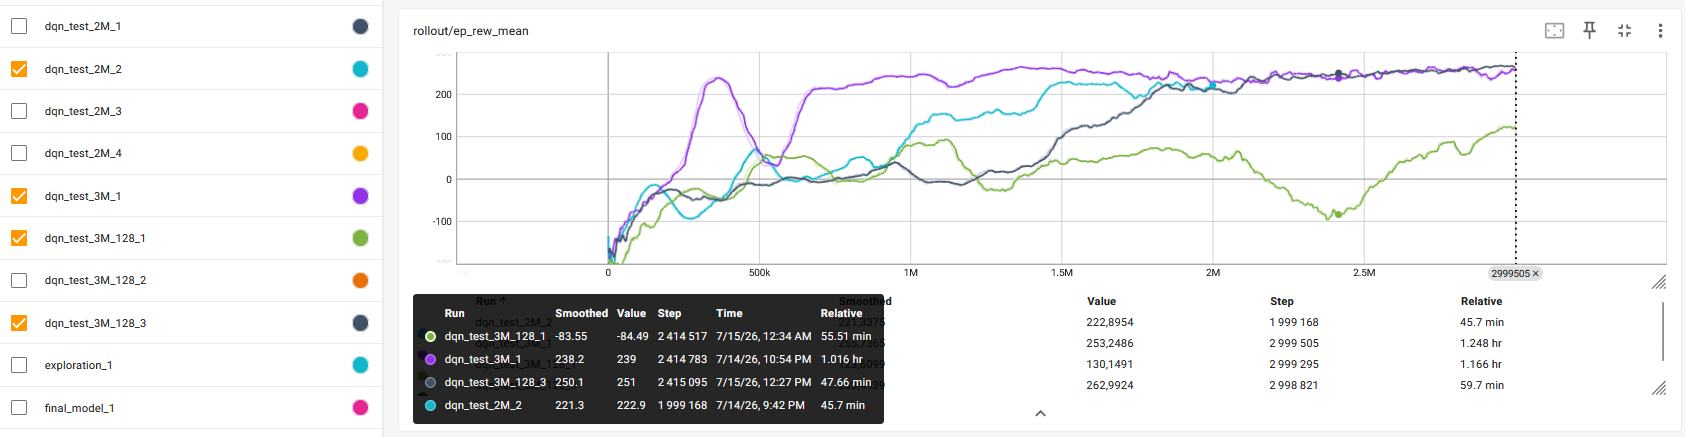

#### TensorBoard

In [56]:
%reload_ext tensorboard
%tensorboard --logdir ./tensorboard_logs/

Reusing TensorBoard on port 6006 (pid 5080), started 0:01:25 ago. (Use '!kill 5080' to kill it.)

### Test Model Final

In [1]:
import os
import gymnasium as gym
from stable_baselines3 import DQN
from gymnasium.wrappers import RecordVideo


# ============================
# Configuration
# ============================

MODEL_PATH = "./model/dqn_lunarlander_final_3"

VIDEO_DIR = "./videos"

TARGET_REWARD = 200

MAX_ATTEMPTS = 20


# Création du dossier vidéo
os.makedirs(VIDEO_DIR, exist_ok=True)


# ============================
# Chargement du modèle
# ============================

print("Chargement du modèle...")

model = DQN.load(MODEL_PATH)

print("Modèle chargé.")


# ============================
# Recherche d'une partie réussie
# ============================

best_reward = -float("inf")
best_episode = 0


for episode in range(MAX_ATTEMPTS):

    print(f"\nEpisode test {episode+1}/{MAX_ATTEMPTS}")


    env = gym.make(
        "LunarLander-v3",
        render_mode="rgb_array"
    )


    # Enregistrement uniquement du meilleur épisode trouvé
    env = RecordVideo(
        env,
        video_folder=VIDEO_DIR,
        name_prefix=f"eagle1_episode_{episode+1}",
        episode_trigger=lambda x: True
    )


    obs, info = env.reset(
        seed=42 + episode
    )


    done = False
    total_reward = 0
    steps = 0


    while not done:


        action, _ = model.predict(
            obs,
            deterministic=True
        )


        obs, reward, terminated, truncated, info = env.step(
            action
        )


        total_reward += reward
        steps += 1


        done = terminated or truncated


    env.close()


    print(
        f"Reward : {total_reward:.2f} | Steps : {steps}"
    )


    if total_reward > best_reward:

        best_reward = total_reward
        best_episode = episode + 1


    if total_reward >= TARGET_REWARD:

        print(
            "\nAtterrissage réussi trouvé !"
        )

        break



# ============================
# Résultat
# ============================

print("\n======================")
print("Résultat final")
print("======================")

print(
    f"Meilleur épisode : {best_episode}"
)

print(
    f"Meilleure récompense : {best_reward:.2f}"
)


print(
    f"\nLes vidéos sont disponibles dans : {VIDEO_DIR}"
)

Chargement du modèle...
Modèle chargé.

Episode test 1/20


h:\python_project\projet11\.venv\Lib\site-packages\gymnasium\wrappers\rendering.py:292: UserWarning: WARN: Overwriting existing videos at h:\python_project\projet11\videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Reward : 269.57 | Steps : 206

Atterrissage réussi trouvé !

Résultat final
Meilleur épisode : 1
Meilleure récompense : 269.57

Les vidéos sont disponibles dans : ./videos


In [3]:
from stable_baselines3 import DQN
import gymnasium as gym


train_env = Monitor(gym.make("LunarLander-v3"))
eval_env = Monitor(gym.make("LunarLander-v3"))

train_env.reset(seed=42)
eval_env.reset(seed=42)

model = DQN(
    "MlpPolicy",
    train_env,
    learning_rate=6.3e-4,
    buffer_size=500000,
    learning_starts=0,
    batch_size=128,
    gamma=0.99,
    train_freq=4,
    gradient_steps=-1,
    target_update_interval=250,
    exploration_fraction=0.1,
    exploration_final_eps=0.05,
    verbose=1,
    tensorboard_log="./tensorboard_logs/"
)

model.learn(
    total_timesteps=100000,
    tb_log_name="dqn_test1_1m_128"
)

# Évaluation sur 100 épisodes
mean_reward, std_reward = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=100,
    deterministic=True
)
print(f"Score final : {mean_reward:.2f} ± {std_reward:.2f}")

#model.save("dqn_lunarlander_final_3")

Using cpu device
Wrapping the env in a DummyVecEnv.
Logging to ./tensorboard_logs/dqn_test1_1m_128_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 94.5     |
|    ep_rew_mean      | -200     |
|    exploration_rate | 0.964    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 357      |
|    time_elapsed     | 1        |
|    total_timesteps  | 378      |
| train/              |          |
|    learning_rate    | 0.00063  |
|    loss             | 1.19     |
|    n_updates        | 376      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 94.6     |
|    ep_rew_mean      | -208     |
|    exploration_rate | 0.928    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 373      |
|    time_elapsed     | 2        |
|    total_timesteps  | 757      |
| train/              | 

In [4]:
train_env = Monitor(gym.make("LunarLander-v3"))
eval_env = Monitor(gym.make("LunarLander-v3"))

train_env.reset(seed=42)
eval_env.reset(seed=42)

model = DQN(
    "MlpPolicy",
    train_env,
    learning_rate=6.3e-4,
    buffer_size=500000,
    learning_starts=0,
    batch_size=128,
    gamma=0.99,
    train_freq=4,
    gradient_steps=-1,
    target_update_interval=250,
    exploration_fraction=0.1,
    exploration_final_eps=0.1,
    verbose=1,
    tensorboard_log="./tensorboard_logs/"
)

model.learn(
    total_timesteps=100000,
    tb_log_name="dqn_test2_1m_128"
)

# Évaluation sur 100 épisodes
mean_reward, std_reward = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=100,
    deterministic=True
)
print(f"Score final : {mean_reward:.2f} ± {std_reward:.2f}")

Using cpu device
Wrapping the env in a DummyVecEnv.
Logging to ./tensorboard_logs/dqn_test2_1m_128_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 106      |
|    ep_rew_mean      | -180     |
|    exploration_rate | 0.962    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 392      |
|    time_elapsed     | 1        |
|    total_timesteps  | 423      |
| train/              |          |
|    learning_rate    | 0.00063  |
|    loss             | 0.738    |
|    n_updates        | 420      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 95.6     |
|    ep_rew_mean      | -144     |
|    exploration_rate | 0.931    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 395      |
|    time_elapsed     | 1        |
|    total_timesteps  | 765      |
| train/              | 

### Evaluation

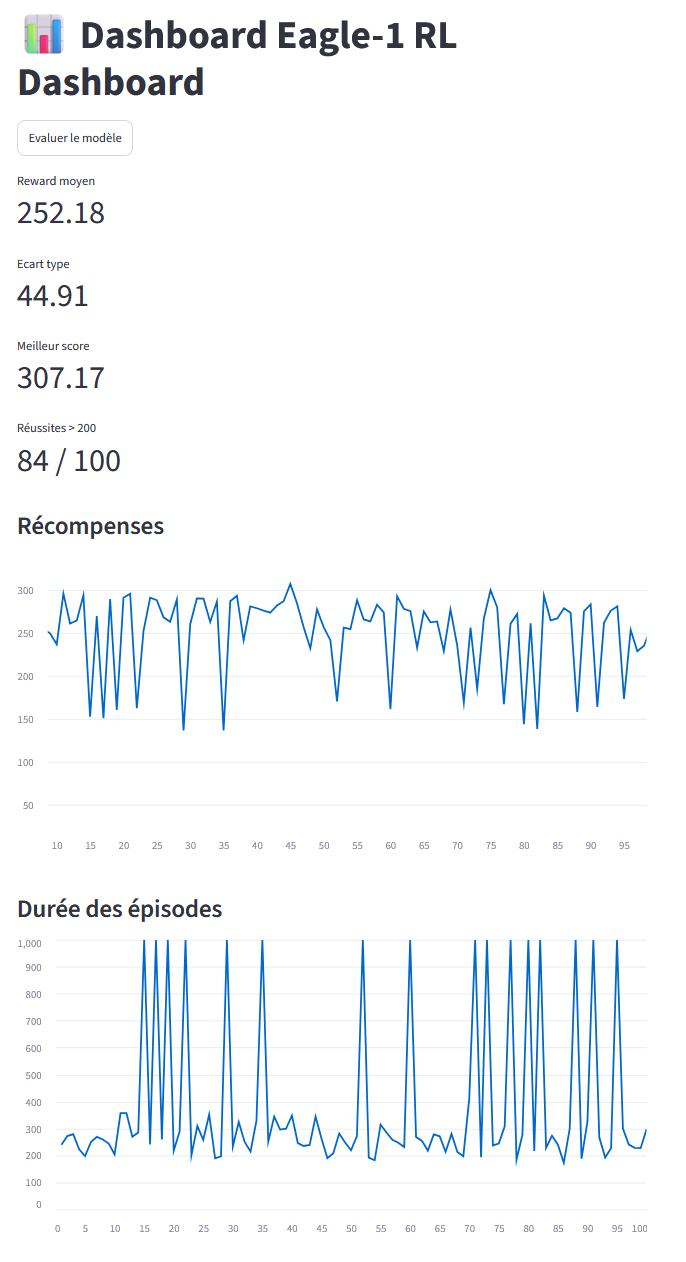